# Лабораторная работа №3. Оптимизация гиперпараметров

**Задача:** предсказать оценку качества красного вина по 11 физико-химическим признакам (Wine Quality, UCI), продолжая задачу регрессии из ЛР №1.

**Основная модель:** градиентный бустинг над деревьями, реализация **XGBoost**. Она выбрана по условию работы; превосходство над моделями прошлой лабораторной здесь не утверждается. GPU-реализация согласована отдельно, это не `sklearn.GradientBoostingRegressor`.

**Дополнительное исследование:** CatBoost с тем же протоколом Grid Search, Random Search и байесовской оптимизации Optuna/TPE.

Основная метрика — **RMSE**, дополнительная — **MAE**. Исходная модель каждой реализации зафиксирована до поиска. Все решения принимаются только на train/CV; test открывается в финальной секции.

При подготовке этой работы использовалась отдельная рабочая копия без выполненной ЛР №1; baseline настоящей работы измерен заново. Порог RMSE < 0.70 из ЛР №1 относится к её скрытому тесту; результат на нашем разбиении не гарантирует прохождение скрытой проверки.

## 1. Воспроизводимость и GPU

В Colab выберите **Runtime → Change runtime type → T4 GPU**, затем **Run all**. Поиски выполняются последовательно: одновременное обучение нескольких кандидатов на одной GPU вызвало бы конкуренцию за ресурсы.

Версии трёх библиотек и scikit-learn зафиксированы; версии остальных пакетов, GPU и хеш данных сохраняются в результатах. `random_state=42` фиксирует разбиения и случайный поиск. CatBoost на GPU допускает небольшие численные различия даже с одинаковым seed из-за порядка суммирования чисел с плавающей точкой.

Все завершённые оценки записываются в Google Drive: `MyDrive/MAI_lab03_hyperparameters/results`. Перед запуском необходимо разрешить Colab доступ к Drive. Результаты каждого кандидата и состояние Optuna сохраняются после завершения его CV-проверки. После обрыва сессии повторный Run all продолжает с сохранённого checkpoint; уже завершённые проверки не повторяются. Промежуточный кандидат, не успевший полностью сохраниться, может быть вычислен заново. Финальный архив дополнительно скачивается на компьютер.


In [4]:
%pip -q install xgboost==3.0.5 catboost==1.2.8 optuna==4.5.0 scikit-learn==1.6.1

In [5]:
import hashlib
import io
import json
import os
import platform
import shutil
import subprocess
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
import catboost
import optuna
from IPython.display import Markdown, display
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, ParameterGrid, ParameterSampler
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

SEED = 42
# Подключать Drive только после разрешения владельца: код Colab получит доступ к его файлам.
from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/MAI_lab03_hyperparameters/results')
ROOT.mkdir(parents=True, exist_ok=True)
(ROOT / 'evaluations').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 115, 'axes.titlesize': 12})
optuna.logging.set_verbosity(optuna.logging.WARNING)

def write_json(path, value):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

try:
    gpu_info = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv'], text=True
    ).strip()
except (OSError, subprocess.CalledProcessError) as exc:
    raise RuntimeError('Для этой работы нужна GPU: Runtime → Change runtime type → T4 GPU.') from exc

versions = {name: module.__version__ for name, module in
            [('numpy', np), ('pandas', pd), ('sklearn', sklearn),
             ('xgboost', xgboost), ('catboost', catboost), ('optuna', optuna)]}
versions.update(python=platform.python_version(), gpu=gpu_info)
print(gpu_info)
display(pd.Series(versions, name='Версия / оборудование').to_frame())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB


,Версия / оборудование
numpy,2.1.3
pandas,2.2.3
sklearn,1.6.1
xgboost,3.0.5
catboost,1.2.8
optuna,4.5.0
python,3.13.16
gpu,"name, driver_version, memory.total [MiB]\nTesl..."


## 2. Данные и честное разбиение

Используется файл `winequality-red.csv` из официального архива [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Цель `quality` — порядковая экспертная оценка, здесь решается задача регрессии. RMSE выражен в баллах качества; MAE — среднее абсолютное отклонение в тех же единицах. Возведение ошибок в квадрат делает RMSE более чувствительным к крупным промахам.

В данных встречаются повторяющиеся наборы признаков. Их нельзя распределять между train/test или обучающими и валидационными частями CV: иначе модель может фактически узнать уже виденный объект. Группы формируются по **всем входным признакам, без target**; одинаковые входы целиком остаются в одной части. Строки и оценки не удаляются и не усредняются.

20% групп откладываем в test. Из-за разного размера групп доля строк может немного отличаться от 20%. Весь последующий анализ данных и подбор выполняется только на оставшихся объектах. Масштабирование деревьям не требуется; пропуски проверяются, преобразования, обучаемые на test, отсутствуют.

Всего 1599 строк; train=1277, test=322; уникальных наборов признаков=1359.
SHA256: 4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000,1277.000
mean,8.296,0.527,0.271,2.539,0.089,15.681,46.491,0.997,3.310,0.657,10.428
std,1.735,0.174,0.195,1.413,0.050,10.330,33.011,0.002,0.152,0.173,1.079
min,4.600,0.160,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400
25%,7.100,0.400,0.100,1.900,0.071,7.000,22.000,0.996,3.210,0.550,9.500
50%,7.900,0.520,0.260,2.200,0.080,14.000,37.000,0.997,3.310,0.620,10.100
75%,9.100,0.635,0.420,2.600,0.091,21.000,63.000,0.998,3.400,0.730,11.100
max,15.900,1.580,1.000,15.500,0.611,72.000,289.000,1.004,3.900,2.000,14.900


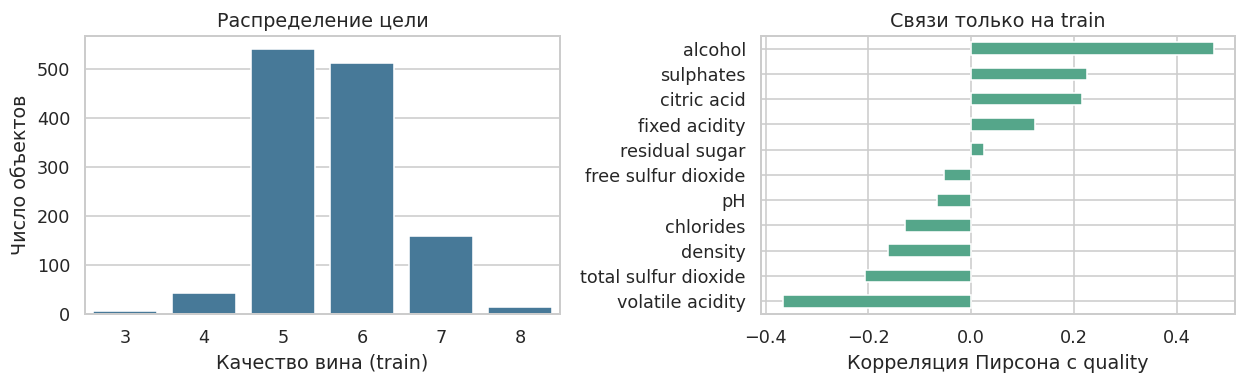

На train самая сильная по модулю линейная связь у **alcohol** (0.471). Это описательная ассоциация, а не причинный эффект. Редкие оценки представлены слабее центральных; поэтому ошибка может зависеть от уровня quality.

In [7]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
raw_path = ROOT / 'winequality-red.csv'
if not raw_path.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    raw_path.write_bytes(archive.read('winequality-red.csv'))

data_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
data = pd.read_csv(raw_path, sep=';')
assert data.shape == (1599, 12), data.shape
assert not data.isna().any().any()
features = data.drop(columns='quality')
groups, _ = pd.factorize(pd.MultiIndex.from_frame(features))
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(outer.split(features, groups=groups))
X_train = features.iloc[train_idx].to_numpy(dtype=np.float32)
y_train = data.quality.iloc[train_idx].to_numpy(dtype=np.float64)
X_test = features.iloc[test_idx].to_numpy(dtype=np.float32)
y_test = data.quality.iloc[test_idx].to_numpy(dtype=np.float64)
groups_train = groups[train_idx]
assert set(groups_train).isdisjoint(groups[test_idx])
cv = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=groups_train))
for tr, va in cv_splits:
    assert set(groups_train[tr]).isdisjoint(groups_train[va])

protocol = dict(version=1, data_sha256=data_hash, seed=SEED, folds=3,
                train_idx=train_idx.tolist(), test_idx=test_idx.tolist(),
                cv_splits=[dict(train=a.tolist(), validation=b.tolist()) for a,b in cv_splits],
                packages={key: value for key, value in versions.items() if key != 'gpu'},
                hardware=gpu_info)
protocol_path = ROOT / 'protocol.json'
if protocol_path.exists():
    previous = json.loads(protocol_path.read_text())
    for key in ['version', 'data_sha256', 'seed', 'folds', 'train_idx', 'test_idx', 'cv_splits', 'packages']:
        if previous[key] != protocol[key]:
            raise RuntimeError(f'Checkpoint несовместим по {key}. Используйте новую папку результатов.')
else:
    write_json(protocol_path, protocol)

print(f'Всего {len(data)} строк; train={len(train_idx)}, test={len(test_idx)}; '
      f'уникальных наборов признаков={len(np.unique(groups))}.')
print('SHA256:', data_hash)
display(features.iloc[train_idx].describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=y_train.astype(int), ax=axes[0], color='#3a7ca5')
axes[0].set(xlabel='Качество вина (train)', ylabel='Число объектов', title='Распределение цели')
train_data = data.iloc[train_idx]
correlations = train_data.corr(numeric_only=True)['quality'].drop('quality').sort_values()
correlations.plot.barh(ax=axes[1], color='#55a68a')
axes[1].set(xlabel='Корреляция Пирсона с quality', title='Связи только на train')
plt.tight_layout(); plt.show()
strongest = correlations.abs().idxmax()
display(Markdown(f'На train самая сильная по модулю линейная связь у **{strongest}** '
                 f'({correlations[strongest]:.3f}). Это описательная ассоциация, а не причинный эффект. '
                 'Редкие оценки представлены слабее центральных; поэтому ошибка может зависеть от уровня quality.'))

### Кросс-валидация и выбор метрики

Используем **3-fold GroupKFold**: в каждом обучении доступны примерно 2/3 train, а каждый объект один раз получает валидационное предсказание. Это компромисс между устойчивостью оценки и стоимостью тысяч GPU-обучений. Все кандидаты и методы используют **те же три разбиения**.

CV усредняет результат нескольких проверок на невиденных при конкретном обучении объектах. Одного train/test разбиения для подбора недостаточно: многократный выбор по test подстраивает решение к случайным особенностям test и делает оценку оптимистичной. Здесь test изолирован до завершения всех поисков и диагностики.

Минимизируем среднее RMSE по folds (не корень из среднего MSE). Также сохраняем RMSE каждого fold, стандартное отклонение с `ddof=1`, train RMSE и MAE на валидации. Разброс по трём folds — описательная характеристика, не доверительный интервал: обучающие выборки folds пересекаются.

In [8]:
FAMILIES = ['XGBoost', 'CatBoost']
BASE_PARAMS = dict(n_estimators=100, learning_rate=0.10, max_depth=3)

def make_model(family, params):
    p = dict(n_estimators=int(params['n_estimators']),
             learning_rate=float(params['learning_rate']),
             max_depth=int(params['max_depth']))
    if family == 'XGBoost':
        return XGBRegressor(**p, objective='reg:squarederror', tree_method='hist',
                            device='cuda', random_state=SEED, n_jobs=2,
                            subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0,
                            min_child_weight=1, max_bin=256)
    if family == 'CatBoost':
        return CatBoostRegressor(iterations=p['n_estimators'], learning_rate=p['learning_rate'],
                                 depth=p['max_depth'], loss_function='RMSE', task_type='GPU',
                                 devices='0', random_seed=SEED, thread_count=2,
                                 l2_leaf_reg=3.0, bootstrap_type='Bayesian',
                                 random_strength=1.0, border_count=128,
                                 verbose=False, allow_writing_files=False)
    raise ValueError(family)

def evaluate(family, params, tag='analysis'):
    params = dict(n_estimators=int(params['n_estimators']),
                  learning_rate=float(params['learning_rate']), max_depth=int(params['max_depth']))
    key = hashlib.sha256(json.dumps([family, params, tag], sort_keys=True).encode()).hexdigest()[:24]
    path = ROOT / 'evaluations' / (key + '.json')
    if path.exists():
        return json.loads(path.read_text())
    started = time.perf_counter()
    train_scores, val_scores, val_mae = [], [], []
    for tr, va in cv_splits:
        model = make_model(family, params)
        model.fit(X_train[tr], y_train[tr])
        train_scores.append(float(root_mean_squared_error(y_train[tr], model.predict(X_train[tr]))))
        pred = model.predict(X_train[va])
        val_scores.append(float(root_mean_squared_error(y_train[va], pred)))
        val_mae.append(float(mean_absolute_error(y_train[va], pred)))
    result = dict(family=family, params=params, train_rmse=float(np.mean(train_scores)),
                  cv_rmse=float(np.mean(val_scores)), cv_std=float(np.std(val_scores, ddof=1)),
                  fold_rmse=val_scores, fold_mae=val_mae,
                  seconds=time.perf_counter()-started)
    write_json(path, result)
    return result

# Baseline — исходный бустинг, а не предсказание константой.
# DummyRegressor будет добавлен в итоговую таблицу как отдельный ориентир.
baseline_path = ROOT / 'baseline.json'
if baseline_path.exists():
    baseline_results = json.loads(baseline_path.read_text())
    assert set(FAMILIES).issubset(baseline_results)
    print('Исходные модели загружены из checkpoint, обучение пропущено.')
else:
    baseline_results = {family: evaluate(family, BASE_PARAMS, 'baseline') for family in FAMILIES}
    write_json(baseline_path, baseline_results)
display(pd.DataFrame([dict(model=f, params=r['params'], CV_RMSE=r['cv_rmse'],
                           CV_std=r['cv_std'], train_RMSE=r['train_rmse'])
                      for f,r in baseline_results.items()]))


Исходные модели загружены из checkpoint, обучение пропущено.


,model,params,CV_RMSE,CV_std,train_RMSE
0,XGBoost,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",0.660317,0.037443,0.455774
1,CatBoost,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",0.650103,0.035547,0.544549


### Оценка длительности перед запуском

Выполняем короткий пилот на первом CV-разбиении, включая простую, среднюю и более дорогую конфигурации. Оценка времени приблизительная: fine-пространство зависит от найденного победителя, а время GPU меняется от глубины дерева. При перезапуске результаты пилота читаются из файла.

Для каждого метода: 64 широкие + 105 уточняющих проверок = **169 конфигураций**, для двух семейств и трёх методов — **1 014 конфигураций / 3 042 CV-обучения**. Кривые обучения и одномерные срезы выполняются отдельно от этого бюджета. Early stopping и pruning отключены, чтобы одинаково проверять все три folds и фиксированное число деревьев.

In [9]:
pilot_path = ROOT / 'pilot.json'
if pilot_path.exists():
    pilot = json.loads(pilot_path.read_text())
else:
    pilot = []
    tr, va = cv_splits[0]
    for family in FAMILIES:
        for n, depth in [(100, 3), (500, 5), (1000, 7)]:
            params = dict(n_estimators=n, learning_rate=0.05, max_depth=depth)
            started = time.perf_counter()
            model = make_model(family, params)
            model.fit(X_train[tr], y_train[tr])
            model.predict(X_train[va])
            if family == 'XGBoost':
                config = json.loads(model.get_booster().save_config())
                assert config['learner']['generic_param']['device'].startswith('cuda')
            else:
                assert model.get_all_params()['task_type'] == 'GPU'
            pilot.append(dict(family=family, **params, fit_seconds=time.perf_counter()-started))
    write_json(pilot_path, pilot)
display(pd.DataFrame(pilot).round(3))
for family in FAMILIES:
    seconds = np.median([r['fit_seconds'] for r in pilot if r['family'] == family])
    print(f'{family}: грубый ориентир на 3 метода: {seconds * 169 * 3 * 3 / 60:.1f} мин; '
          'погрешность большая, точное время сохраняется в поиске.')

,family,n_estimators,learning_rate,max_depth,fit_seconds
0,XGBoost,100,0.05,3,0.483
1,XGBoost,500,0.05,5,2.231
2,XGBoost,1000,0.05,7,5.784
3,CatBoost,100,0.05,3,0.961
4,CatBoost,500,0.05,5,3.597
5,CatBoost,1000,0.05,7,15.523


XGBoost: грубый ориентир на 3 метода: 56.5 мин; погрешность большая, точное время сохраняется в поиске.
CatBoost: грубый ориентир на 3 метода: 91.2 мин; погрешность большая, точное время сохраняется в поиске.


## 3. Что оптимизируем и почему

Основная модель — **градиентный бустинг XGBoost**, выбранный по условию работы; **CatBoost** — дополнительное исследование. Для каждой реализации исходный baseline и все стратегии поиска используют одни и те же разбиения. Оптимизируем три параметра, отвечающие за ёмкость модели и скорость её наращивания:

| Параметр | Смысл | Широкая сетка Grid Search | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` (`iterations` в CatBoost) | Число деревьев | 100, 300, 600, 1000 | Слишком мало деревьев может дать недообучение; увеличение повышает время и иногда переобучение. Эффект зависит от `learning_rate`. |
| `learning_rate` | Вклад очередного дерева | 0.01, 0.03, 0.10, 0.20 | Малый шаг обычно требует больше деревьев; большой быстрее уменьшает train-ошибку, но может ухудшать обобщение. |
| `max_depth` (`depth` в CatBoost) | Максимальная глубина дерева | 2, 4, 6, 8 | Глубокие деревья описывают сложные взаимодействия, но способны запоминать шум. |

Остальные параметры зафиксированы в `make_model`. Добавлять много измерений только ради количества комбинаций не требуется. Глубина в XGBoost и CatBoost не задаёт полностью одинаковую сложность: реализации строят деревья по-разному.

**Два этапа.** Сначала Grid проверяет $4\cdot4\cdot4=64$ комбинации. Затем вокруг собственного лучшего результата каждого метода строится область уточнения: 7 значений числа деревьев, 5 значений шага, 3 глубины — ещё **105 комбинаций** для Grid. Random Search и Optuna получают такие же бюджеты **64 + 105 = 169 полных CV-проверок на реализацию**. Уточнённые области методов могут различаться: каждый метод использует только результаты своего первого этапа. Лучший результат выбирается среди обоих этапов, поэтому неудачное уточнение не теряет прежнего победителя.

Random и Optuna ищут число деревьев и глубину среди целых чисел, а шаг — непрерывно в логарифмическом масштабе. Их широкие границы совпадают с крайними значениями широкой сетки. В уточнении первый кандидат — найденный ранее победитель. Это сравнение процедур с одинаковым числом полных проверок, а не утверждение о глобальном оптимуме по всем возможным параметрам.

### Кросс-валидация и честность сравнения

Используем **3 заранее зафиксированных folds** на обучающей части. Это компромисс между устойчивостью оценки и стоимостью: на каждый набор параметров приходится три обучения, а полный основной поиск содержит $2\cdot3\cdot169\cdot3=3042$ обучения. Группы совпадающих признаков не разделяются между train и validation.

Кросс-валидация показывает, насколько результат зависит от конкретной обучающей части. Одного train/test-разбиения для подбора недостаточно: множество решений быстро подстраивается под случайные особенности единственной проверочной выборки. При повторном выборе параметров по test он фактически становится validation, а итоговая оценка получается оптимистичной. Поэтому в подборе, исследовании параметров и кривых обучения **test не используется**.

Минимизируем **среднее RMSE по folds**; `cv_std` — стандартное отклонение трёх fold-RMSE, а не доверительный интервал. Для каждого кандидата сохраняем также train-RMSE и значения MAE по folds. Early stopping и pruning отключены: все кандидаты проходят полные три обучения с указанным числом деревьев. Кандидаты и folds выполняются последовательно, чтобы не конкурировать за одну GPU.

Бюджет выровнен по числу полных CV-проверок. Фактическое время может различаться из-за выбранных глубин, числа деревьев и работы оптимизатора; поэтому покажем и число проверок, и измеренное время. Один запуск не доказывает универсального превосходства стратегии.

In [10]:
import pickle

COARSE_GRID = {
    'n_estimators': [100, 300, 600, 1000],
    'learning_rate': [0.01, 0.03, 0.10, 0.20],
    'max_depth': [2, 4, 6, 8],
}
N_COARSE, N_FINE = 64, 105
SEARCH_SEED = 42
FAMILIES = ['XGBoost', 'CatBoost']


def clean_params(p):
    return {
        'n_estimators': int(p['n_estimators']),
        'learning_rate': float(p['learning_rate']),
        'max_depth': int(p['max_depth']),
    }


def fine_grid(p):
    """Семь значений числа деревьев; точный incumbent всегда включён."""
    n = int(p['n_estimators'])
    n_values = [int(round(n * m / 10) * 10) for m in np.linspace(0.6, 1.4, 7)]
    n_values[3] = n
    grid = {
        'n_estimators': sorted(set(n_values)),
        'learning_rate': [float(p['learning_rate']) * m
                          for m in [0.6, 0.8, 1.0, 1.2, 1.4]],
        'max_depth': list(range(int(p['max_depth']) - 1, int(p['max_depth']) + 2)),
    }
    assert len(ParameterGrid(grid)) == N_FINE
    assert clean_params(p) in list(ParameterGrid(grid))
    return grid


def bounds_from_grid(grid):
    return {name: [min(values), max(values)] for name, values in grid.items()}


def random_space(bounds):
    return {
        'n_estimators': randint(int(bounds['n_estimators'][0]),
                                int(bounds['n_estimators'][1]) + 1),
        'learning_rate': loguniform(*bounds['learning_rate']),
        'max_depth': randint(int(bounds['max_depth'][0]),
                             int(bounds['max_depth'][1]) + 1),
    }


def atomic_pickle(path, value):
    temp = path.with_suffix(path.suffix + '.tmp')
    with temp.open('wb') as stream:
        pickle.dump(value, stream, protocol=pickle.HIGHEST_PROTOCOL)
    temp.replace(path)


# Полные планы и фактические области уточнения сохраняются рядом с результатами.
write_json(ROOT / 'search_protocol.json', {
    'coarse_grid': COARSE_GRID, 'coarse_bounds': bounds_from_grid(COARSE_GRID),
    'n_coarse': N_COARSE, 'n_fine': N_FINE, 'cv_folds': len(cv_splits),
    'seed': SEARCH_SEED, 'pruning': False, 'early_stopping': False,
})

### 4. Grid Search и Random Search

Для Grid Search используем `ParameterGrid`: это полный перебор зафиксированной сетки. Для Random Search — `ParameterSampler` с независимыми распределениями параметров. Ручной цикл оставляет видимыми все три CV-обучения и позволяет сохранять каждый завершённый кандидат.

План случайного поиска сохраняется до обучения. После прерывания продолжаем с первого незавершённого кандидата; уже выполненное обучение не перезапускаем. Кеш изолирован по реализации, методу, этапу и номеру кандидата: один метод не получает преимущество во времени за счёт вычислений другого. Время ниже — активное время выбора и CV-оценки кандидатов; загрузка данных, графики и паузы между сессиями в него не входят.

In [11]:
def fixed_stage(family, method, stage, plan, first_order):
    path = ROOT / f'{family}_{method}_{stage}.json'
    if path.exists():
        state = json.loads(path.read_text())
        assert state['plan'] == plan, 'Изменился план: остановка без пересчёта.'
        assert all(row['params'] == plan[i] for i, row in enumerate(state['rows']))
        print(f"Checkpoint {family} / {method} / {stage}: {len(state['rows'])}/{len(plan)} уже готово, пропускаем.", flush=True)
    else:
        state = {'plan': plan, 'rows': []}
        write_json(path, state)

    for i in range(len(state['rows']), len(plan)):
        started = time.perf_counter()
        result = evaluate(family, plan[i], tag=f'{method}:{stage}:{i}')
        # Если CV успела сохраниться перед разрывом сессии, учитываем её исходное время.
        active_seconds = max(time.perf_counter() - started, float(result['seconds']))
        row = dict(result, stage=stage, order=first_order + i,
                   search_seconds=active_seconds)
        state['rows'].append(row)
        write_json(path, state)
        if (i + 1) % 10 == 0 or i + 1 == len(plan):
            best = min(r['cv_rmse'] for r in state['rows'])
            print(f'{family} | {method} | {stage}: {i+1}/{len(plan)}, '
                  f'best CV RMSE={best:.4f}', flush=True)
    return state['rows']


def run_grid_or_random(family, method):
    if method == 'Grid':
        coarse_plan = [clean_params(p) for p in ParameterGrid(COARSE_GRID)]
    else:
        coarse_plan = [clean_params(p) for p in ParameterSampler(
            random_space(bounds_from_grid(COARSE_GRID)), n_iter=N_COARSE,
            random_state=SEARCH_SEED)]
    coarse_rows = fixed_stage(family, method, 'coarse', coarse_plan, first_order=1)
    incumbent = min(coarse_rows, key=lambda row: row['cv_rmse'])
    grid = fine_grid(incumbent['params'])
    write_json(ROOT / f'{family}_{method}_fine_space.json', grid)
    if method == 'Grid':
        fine_plan = [clean_params(p) for p in ParameterGrid(grid)]
    else:
        fine_plan = [clean_params(incumbent['params'])] + [clean_params(p) for p in
            ParameterSampler(random_space(bounds_from_grid(grid)),
                             n_iter=N_FINE - 1, random_state=SEARCH_SEED + 1)]
    fine_rows = fixed_stage(family, method, 'fine', fine_plan, first_order=N_COARSE + 1)
    rows = coarse_rows + fine_rows
    return {
        'best': min(rows, key=lambda row: row['cv_rmse']), 'rows': rows,
        'seconds': sum(row['search_seconds'] for row in rows),
        'n_candidates': len(rows),
    }

### 5. Байесовская оптимизация Optuna

Используем **TPE (Tree-structured Parzen Estimator)**. В отличие от независимого случайного выбора TPE накапливает историю и чаще проверяет области параметров, похожие на уже удачные. Первые 10 trials каждого этапа служат случайной разведкой. `multivariate=True` позволяет учитывать совместное поведение параметров, например связь числа деревьев и шага обучения.

Широкий и уточнённый этапы — отдельные `study`, поскольку границы пространства меняются. Вторая study начинает с победителя первого этапа. Это локальное уточнение вокруг найденной области; оно не гарантирует, что перспективные области вне неё отсутствуют. После каждого trial сохраняется сама study вместе с состоянием генератора TPE, что позволяет продолжить поиск после прерывания. Pickle читается только из собственной папки эксперимента.

In [12]:
def optuna_stage(family, stage, bounds, n_trials, first_order, incumbent=None):
    path = ROOT / f'{family}_Optuna_{stage}.pkl'
    if path.exists():
        with path.open('rb') as stream:
            state = pickle.load(stream)
        assert state['bounds'] == bounds, 'Изменились границы study.'
    else:
        study = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(
                seed=SEARCH_SEED, n_startup_trials=10, multivariate=True),
            study_name=f'{family}_{stage}',
        )
        if incumbent is not None:
            study.enqueue_trial(clean_params(incumbent))
        state = {'study': study, 'bounds': bounds, 'rows': []}
        atomic_pickle(path, state)
    study = state['study']

    for i in range(len(state['rows']), n_trials):
        started = time.perf_counter()
        trial = study.ask()
        params = {
            'n_estimators': trial.suggest_int('n_estimators', *bounds['n_estimators']),
            'learning_rate': trial.suggest_float('learning_rate', *bounds['learning_rate'], log=True),
            'max_depth': trial.suggest_int('max_depth', *bounds['max_depth']),
        }
        result = evaluate(family, clean_params(params), tag=f'Optuna:{stage}:{i}')
        study.tell(trial, result['cv_rmse'])
        active_seconds = max(time.perf_counter() - started, float(result['seconds']))
        state['rows'].append(dict(result, stage=stage, order=first_order + i,
                                  search_seconds=active_seconds))
        atomic_pickle(path, state)
        if (i + 1) % 10 == 0 or i + 1 == n_trials:
            print(f'{family} | Optuna | {stage}: {i+1}/{n_trials}, '
                  f'best CV RMSE={study.best_value:.4f}', flush=True)
    study.trials_dataframe().to_csv(ROOT / f'{family}_Optuna_{stage}_trials.csv', index=False)
    return state['rows']


def run_optuna(family):
    coarse_rows = optuna_stage(family, 'coarse', bounds_from_grid(COARSE_GRID),
                               N_COARSE, first_order=1)
    incumbent = min(coarse_rows, key=lambda row: row['cv_rmse'])
    grid = fine_grid(incumbent['params'])
    write_json(ROOT / f'{family}_Optuna_fine_space.json', grid)
    fine_rows = optuna_stage(family, 'fine', bounds_from_grid(grid), N_FINE,
                             first_order=N_COARSE + 1, incumbent=incumbent['params'])
    rows = coarse_rows + fine_rows
    return {
        'best': min(rows, key=lambda row: row['cv_rmse']), 'rows': rows,
        'seconds': sum(row['search_seconds'] for row in rows),
        'n_candidates': len(rows),
    }

### 6. Основной поиск

Ниже выполняются все шесть поисков: три метода для XGBoost и затем те же три метода для CatBoost. Завершённые кандидаты подхватываются из checkpoint. При изменении данных, разбиений, исходных настроек модели или библиотек следует выбрать новую папку эксперимента, чтобы не смешивать разные запуски.

In [13]:
summary_path = ROOT / 'search_summary.json'
search_results = json.loads(summary_path.read_text()) if summary_path.exists() else {}
for family in FAMILIES:
    search_results.setdefault(family, {})
    for method in ['Grid', 'Random', 'Optuna']:
        completed = search_results[family].get(method)
        if completed is not None:
            assert completed['n_candidates'] == len(completed['rows']) == N_COARSE + N_FINE
            assert all(len(row['fold_rmse']) == len(cv_splits) for row in completed['rows'])
            print(f'{family} / {method}: загружены все 169 проверок из checkpoint, обучение пропущено.', flush=True)
            continue
        print(f'\nПродолжение: {family}, {method}', flush=True)
        if method == 'Optuna':
            result = run_optuna(family)
        else:
            result = run_grid_or_random(family, method)
        assert result['n_candidates'] == N_COARSE + N_FINE
        search_results[family][method] = result
        write_json(summary_path, search_results)
        shutil.make_archive('/content/lab03_checkpoint', 'zip', ROOT.parent, ROOT.name)
        print(f"Готово: CV RMSE={result['best']['cv_rmse']:.4f}; "
              f"параметры={result['best']['params']}; "
              f"активное время={result['seconds']/60:.1f} мин", flush=True)


XGBoost / Grid: загружены все 169 проверок из checkpoint, обучение пропущено.
XGBoost / Random: загружены все 169 проверок из checkpoint, обучение пропущено.
XGBoost / Optuna: загружены все 169 проверок из checkpoint, обучение пропущено.
CatBoost / Grid: загружены все 169 проверок из checkpoint, обучение пропущено.
CatBoost / Random: загружены все 169 проверок из checkpoint, обучение пропущено.
CatBoost / Optuna: загружены все 169 проверок из checkpoint, обучение пропущено.


### Как читать сравнение методов

Grid Search гарантированно проверяет каждую комбинацию своей сетки, но быстро дорожает с добавлением измерений и тратит проверки на второстепенные параметры. Random Search особенно полезен, когда важны только несколько параметров: больше различных значений важных координат исследуется без полного декартова произведения. При малом числе измерений и удачной сетке Grid может быть очень конкурентоспособен.

TPE использует прошлые оценки для выбора следующих кандидатов, но тоже не гарантирует победу: CV шумит, первые trials случайны, а локальное уточнение зависит от найденной области. Сравним измеренные результаты этой задачи, количество проверок и время. Разница CV в несколько тысячных при заметном разбросе folds сама по себе не означает устойчивого превосходства метода.

## 7. Сравнение стратегий поиска

Во всех трёх стратегиях минимизируется **средний RMSE на одних и тех же трёх CV-folds**. Метрики ниже положительные: меньше — лучше. У каждого метода собственный широкий этап и собственное уточнение, построенное только по результатам его широкого этапа. В итог идёт лучший кандидат из обоих этапов.

Сопоставимы число запрошенных конфигураций и число полных CV-обучений на одну конфигурацию. Равное число конфигураций не означает равное время: глубокие деревья и большое число итераций дороже. Повторяющиеся параметры внутри бюджета тоже проходят полную CV-проверку; кеш используется только для продолжения прерванного кандидата. Отдельно показаны уникальные комбинации и измеренное время. Единственный запуск с одним seed позволяет сравнить эти эксперименты, но не доказывает универсальное превосходство оптимизатора.

,Модель,Поиск,Конфигурации,Уникальные комбинации,CV RMSE,CV std,"Время, мин"
0,XGBoost,Grid,169,168,0.65363,0.03430,3.84287
1,XGBoost,Random,169,168,0.65338,0.03441,4.05932
2,XGBoost,Optuna,169,168,0.65187,0.03504,1.75914
3,CatBoost,Grid,169,168,0.64791,0.03496,37.74666
4,CatBoost,Random,169,168,0.64778,0.03318,59.71474
5,CatBoost,Optuna,169,168,0.64709,0.03368,70.22455


,Модель,Поиск,n_estimators,learning_rate,max_depth
0,XGBoost,Grid,360,0.013999999999999999,3
1,XGBoost,Random,540,0.00946476337852335,3
2,XGBoost,Optuna,121,0.033159130986049404,3
3,CatBoost,Grid,840,0.006,6
4,CatBoost,Random,647,0.00826953869083084,8
5,CatBoost,Optuna,646,0.008035309792147092,8


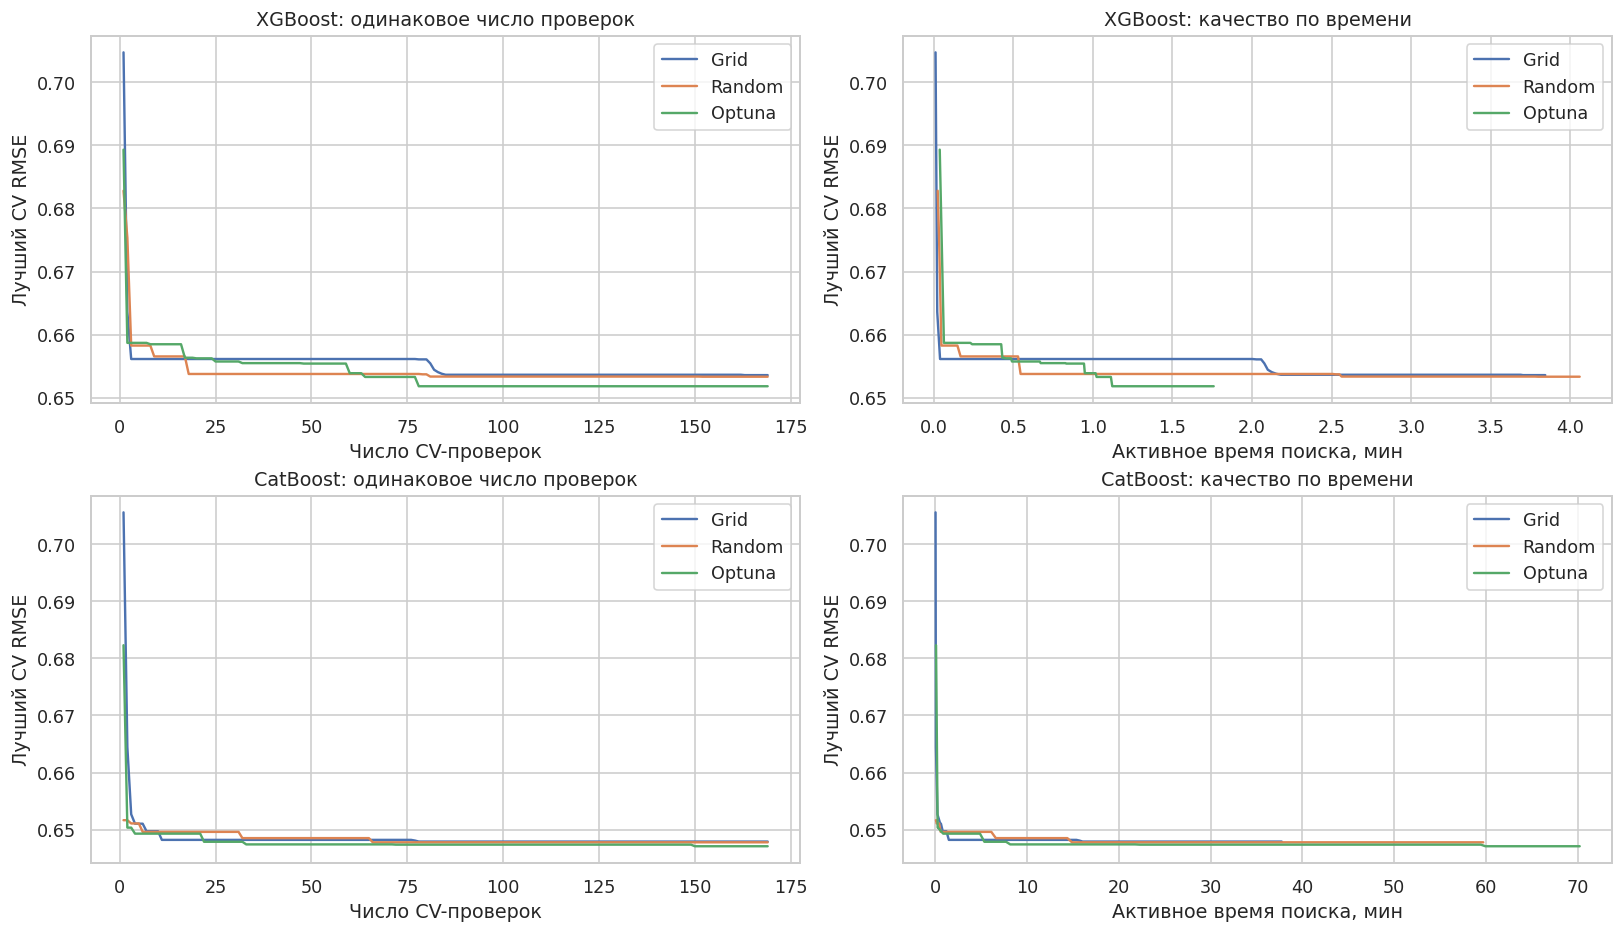

In [26]:
comparison_rows = []
for family, methods in search_results.items():
    for method, result in methods.items():
        best = result['best']
        unique = {json.dumps(r['params'], sort_keys=True) for r in result['rows']}
        comparison_rows.append({
            'Модель': family, 'Поиск': method,
            'Конфигурации': result['n_candidates'],
            'Уникальные комбинации': len(unique),
            'CV RMSE': best['cv_rmse'], 'CV std': best['cv_std'],
            'Время, мин': result['seconds'] / 60,
            'Параметры': json.dumps(best['params'], ensure_ascii=False, sort_keys=True),
        })
search_comparison = pd.DataFrame(comparison_rows)
display(search_comparison.drop(columns='Параметры').round(5))
# Отдельные колонки показывают каждый лучший набор целиком, без многоточий.
best_parameters = pd.DataFrame([
    {'Модель': family, 'Поиск': method,
     'n_estimators': result['best']['params']['n_estimators'],
     'learning_rate': repr(result['best']['params']['learning_rate']),
     'max_depth': result['best']['params']['max_depth']}
    for family, methods in search_results.items() for method, result in methods.items()
])
display(best_parameters)
search_comparison.to_csv(ROOT / 'search_comparison.csv', index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for row, (family, methods) in enumerate(search_results.items()):
    for method, result in methods.items():
        best_so_far = np.minimum.accumulate([r['cv_rmse'] for r in result['rows']])
        elapsed_minutes = np.cumsum([r['search_seconds'] for r in result['rows']]) / 60
        axes[row, 0].plot(np.arange(1, len(best_so_far)+1), best_so_far, label=method)
        axes[row, 1].plot(elapsed_minutes, best_so_far, label=method)
    axes[row, 0].set(title=f'{family}: одинаковое число проверок', xlabel='Число CV-проверок', ylabel='Лучший CV RMSE')
    axes[row, 1].set(title=f'{family}: качество по времени', xlabel='Активное время поиска, мин', ylabel='Лучший CV RMSE')
    axes[row, 0].legend(); axes[row, 1].legend()
fig.savefig(ROOT / 'search_progress.png', dpi=160)
plt.show()


## 8. Влияние гиперпараметров

Для графиков меняем **один параметр**, сохраняя остальные параметры лучшего найденного решения фиксированными. Это позволяет отделить его эффект от одновременного изменения других параметров. Сравниваем train и CV, без обращения к test.

- `n_estimators` — число деревьев. Слишком мало деревьев может не успеть описать зависимость; дальнейший рост иногда уменьшает только train-ошибку.
- `learning_rate` — вклад очередного дерева. Малый шаг требует большего числа деревьев, большой шаг способен быстро подогнать обучающую выборку и ухудшить обобщение.
- `max_depth` — максимальная глубина дерева. Рост глубины увеличивает сложность взаимодействий и возможность запоминания отдельных объектов.

Это локальные срезы поверхности качества: зависимости параметров, особенно числа деревьев и шага, сохраняются. Лучшее значение на одном срезе не является доказательством глобального оптимума.

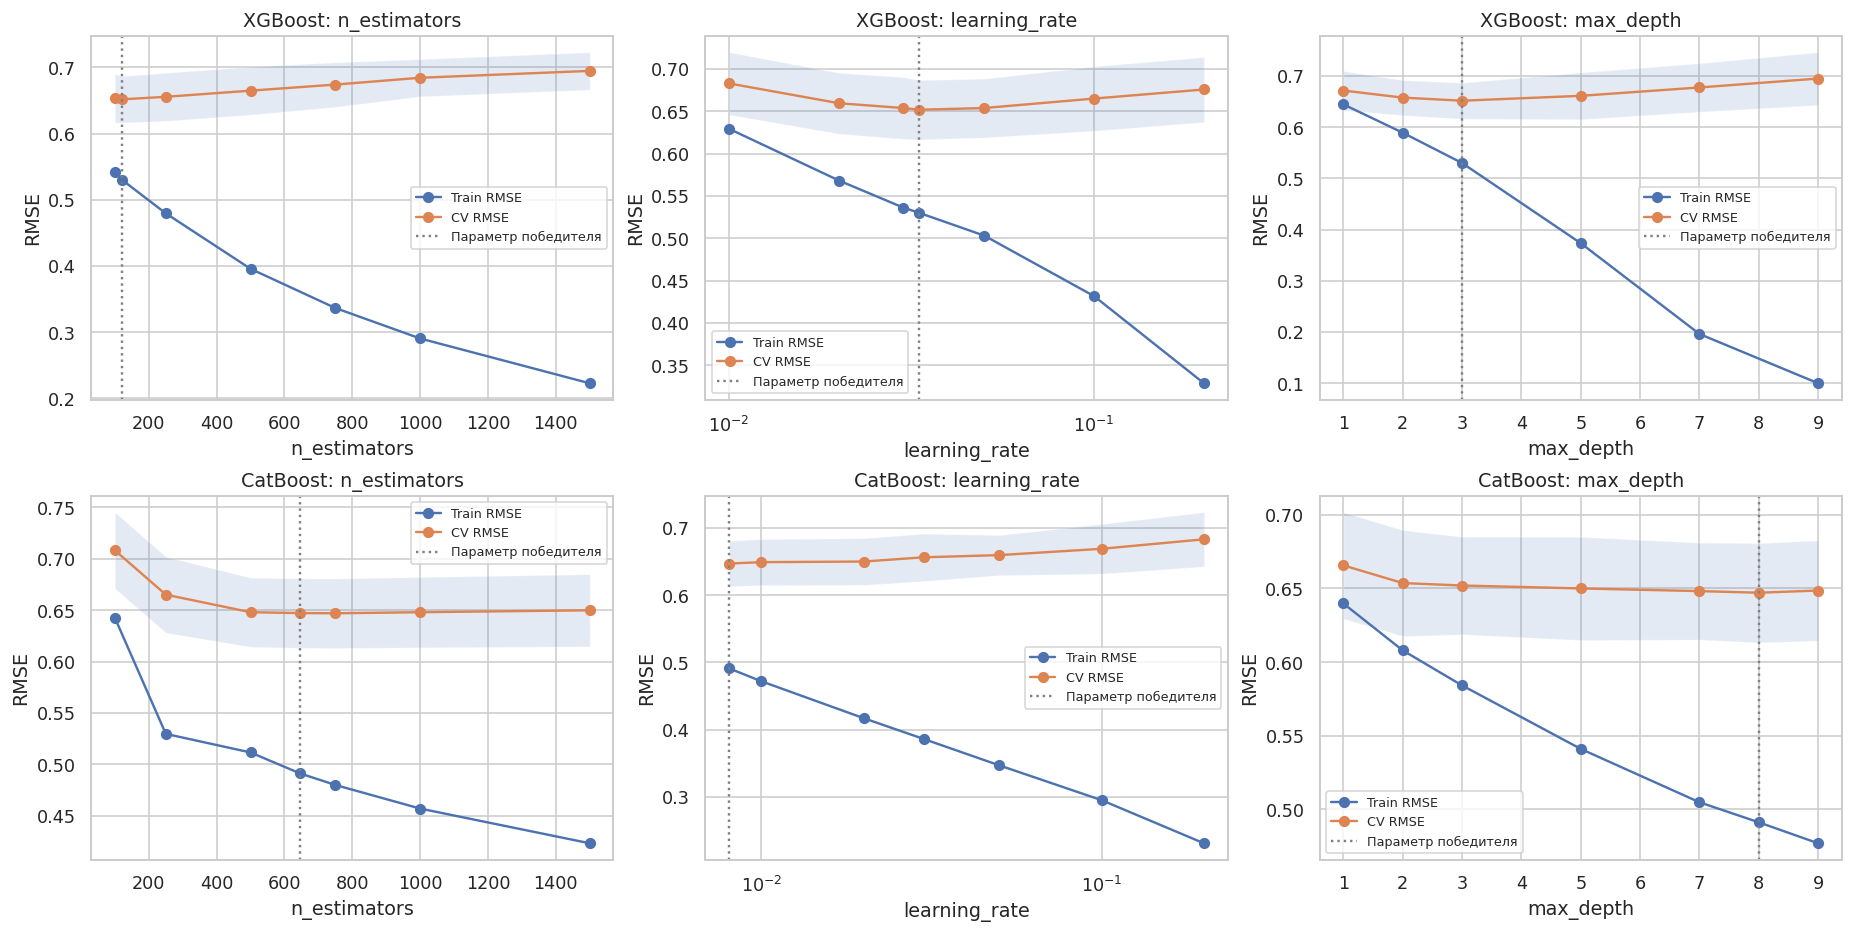

In [15]:
# Выбранные конфигурации определяются по поиску, до просмотра test.
search_winners = {
    family: min([baseline_results[family]] + [r['best'] for r in methods.values()], key=lambda r: r['cv_rmse'])
    for family, methods in search_results.items()
}
parameter_values = {
    'n_estimators': [100, 250, 500, 750, 1000, 1500],
    'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.1, 0.2],
    'max_depth': [1, 2, 3, 5, 7, 9],
}
influence_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for row, family in enumerate(search_results):
    anchor = search_winners[family]['params']
    for col, (parameter, values) in enumerate(parameter_values.items()):
        values = sorted(set(values + [anchor[parameter]]))
        results = []
        for value in values:
            params = dict(anchor, **{parameter: value})
            result = evaluate(family, params, tag=f'influence_{parameter}')
            results.append(result)
            influence_rows.append({
                'family': family, 'parameter': parameter, 'value': value,
                'train_rmse': result['train_rmse'], 'cv_rmse': result['cv_rmse'],
                'cv_std': result['cv_std'], 'params': json.dumps(params, sort_keys=True),
            })
        ax = axes[row, col]
        train = np.array([r['train_rmse'] for r in results])
        valid = np.array([r['cv_rmse'] for r in results])
        std = np.array([r['cv_std'] for r in results])
        ax.plot(values, train, 'o-', label='Train RMSE')
        ax.plot(values, valid, 'o-', label='CV RMSE')
        ax.fill_between(values, valid-std, valid+std, alpha=0.15)
        ax.axvline(anchor[parameter], linestyle=':', color='gray', label='Параметр победителя')
        if parameter == 'learning_rate':
            ax.set_xscale('log')
        ax.set(title=f'{family}: {parameter}', xlabel=parameter, ylabel='RMSE')
        ax.legend(fontsize=8)
pd.DataFrame(influence_rows).to_csv(ROOT / 'parameter_influence.csv', index=False)
fig.savefig(ROOT / 'parameter_influence.png', dpi=160)
plt.show()

## 9. Кривые обучения: недообучение и переобучение

На оси X — размер обучающей части внутри fold, на оси Y — train/CV RMSE. Валидационная часть каждого fold неизменна. Обучающие подвыборки вложены друг в друга; одинаковые по признакам объекты берутся целыми группами и не попадают одновременно в train и validation.

Сравним три заранее заданных режима для каждой реализации:

| Режим | Число деревьев | learning rate | Глубина |
|---|---:|---:|---:|
| Простая модель | 50 | 0.01 | 1 |
| Выбрана по CV | результат поиска | результат поиска | результат поиска |
| Сложная модель | 1500 | 0.1 | 9 |

Название «сложная» описывает параметры, а не заранее установленный диагноз. **Недообучение** предполагается, когда train-ошибка велика, близка к CV и почти не снижается с ростом выборки. **Переобучение** предполагается при малой train-ошибке и заметно большей CV-ошибке; особенно показательно, если рост сложности улучшает только train. Большой разрыв сам по себе не даёт универсального порога диагноза: важны величина ошибки, сравнение режимов и изменение кривых.

Полосы показывают ± одно стандартное отклонение между folds. Это описание разброса, не доверительный интервал: обучающие части folds пересекаются.

In [16]:
import hashlib

fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
curve_cache_path = ROOT / 'learning_curves.json'
curve_cache = json.loads(curve_cache_path.read_text()) if curve_cache_path.exists() else {}
curve_rows = []
# Отпечаток не позволяет применить кеш к изменённым данным или разбиениям.
curve_data_signature = hashlib.sha256(
    X_train.tobytes() + np.asarray(y_train).tobytes()
    + np.asarray(groups_train).tobytes()
).hexdigest()

for family in search_results:
    curve_models = {
        'Простая': {'n_estimators': 50, 'learning_rate': 0.01, 'max_depth': 1},
        'Выбрана по CV': search_winners[family]['params'],
        'Сложная': {'n_estimators': 1500, 'learning_rate': 0.1, 'max_depth': 9},
    }
    for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
        rng = np.random.default_rng(4200 + fold)
        group_order = rng.permutation(np.unique(groups_train[fit_idx]))
        for fraction in fractions:
            n_groups = max(2, int(np.ceil(fraction * len(group_order))))
            chosen_groups = group_order[:n_groups]
            subset = fit_idx[np.isin(groups_train[fit_idx], chosen_groups)]
            assert not set(groups_train[subset]) & set(groups_train[valid_idx])
            split_signature = hashlib.sha256(subset.tobytes()+valid_idx.tobytes()).hexdigest()
            for regime, params in curve_models.items():
                key = json.dumps([curve_data_signature, split_signature, family, params], sort_keys=True)
                if key not in curve_cache:
                    model = make_model(family, params)
                    model.fit(X_train[subset], y_train[subset])
                    curve_cache[key] = {
                        'family': family, 'regime': regime, 'fold': fold,
                        'fraction': fraction, 'n_train': len(subset),
                        'train_rmse': float(np.sqrt(np.mean((y_train[subset]-model.predict(X_train[subset]))**2))),
                        'cv_rmse': float(np.sqrt(np.mean((y_train[valid_idx]-model.predict(X_train[valid_idx]))**2))),
                    }
                    temporary = curve_cache_path.with_suffix('.tmp')
                    temporary.write_text(json.dumps(curve_cache, ensure_ascii=False, indent=2))
                    temporary.replace(curve_cache_path)
                    del model
                curve_rows.append(dict(curve_cache[key], regime=regime, fold=fold, fraction=fraction))
        print(f'{family}: кривые обучения, fold {fold}/{len(cv_splits)} завершён', flush=True)
curve_df = pd.DataFrame(curve_rows)
curve_df.to_csv(ROOT / 'learning_curves.csv', index=False)

XGBoost: кривые обучения, fold 1/3 завершён
XGBoost: кривые обучения, fold 2/3 завершён
XGBoost: кривые обучения, fold 3/3 завершён
CatBoost: кривые обучения, fold 1/3 завершён
CatBoost: кривые обучения, fold 2/3 завершён
CatBoost: кривые обучения, fold 3/3 завершён


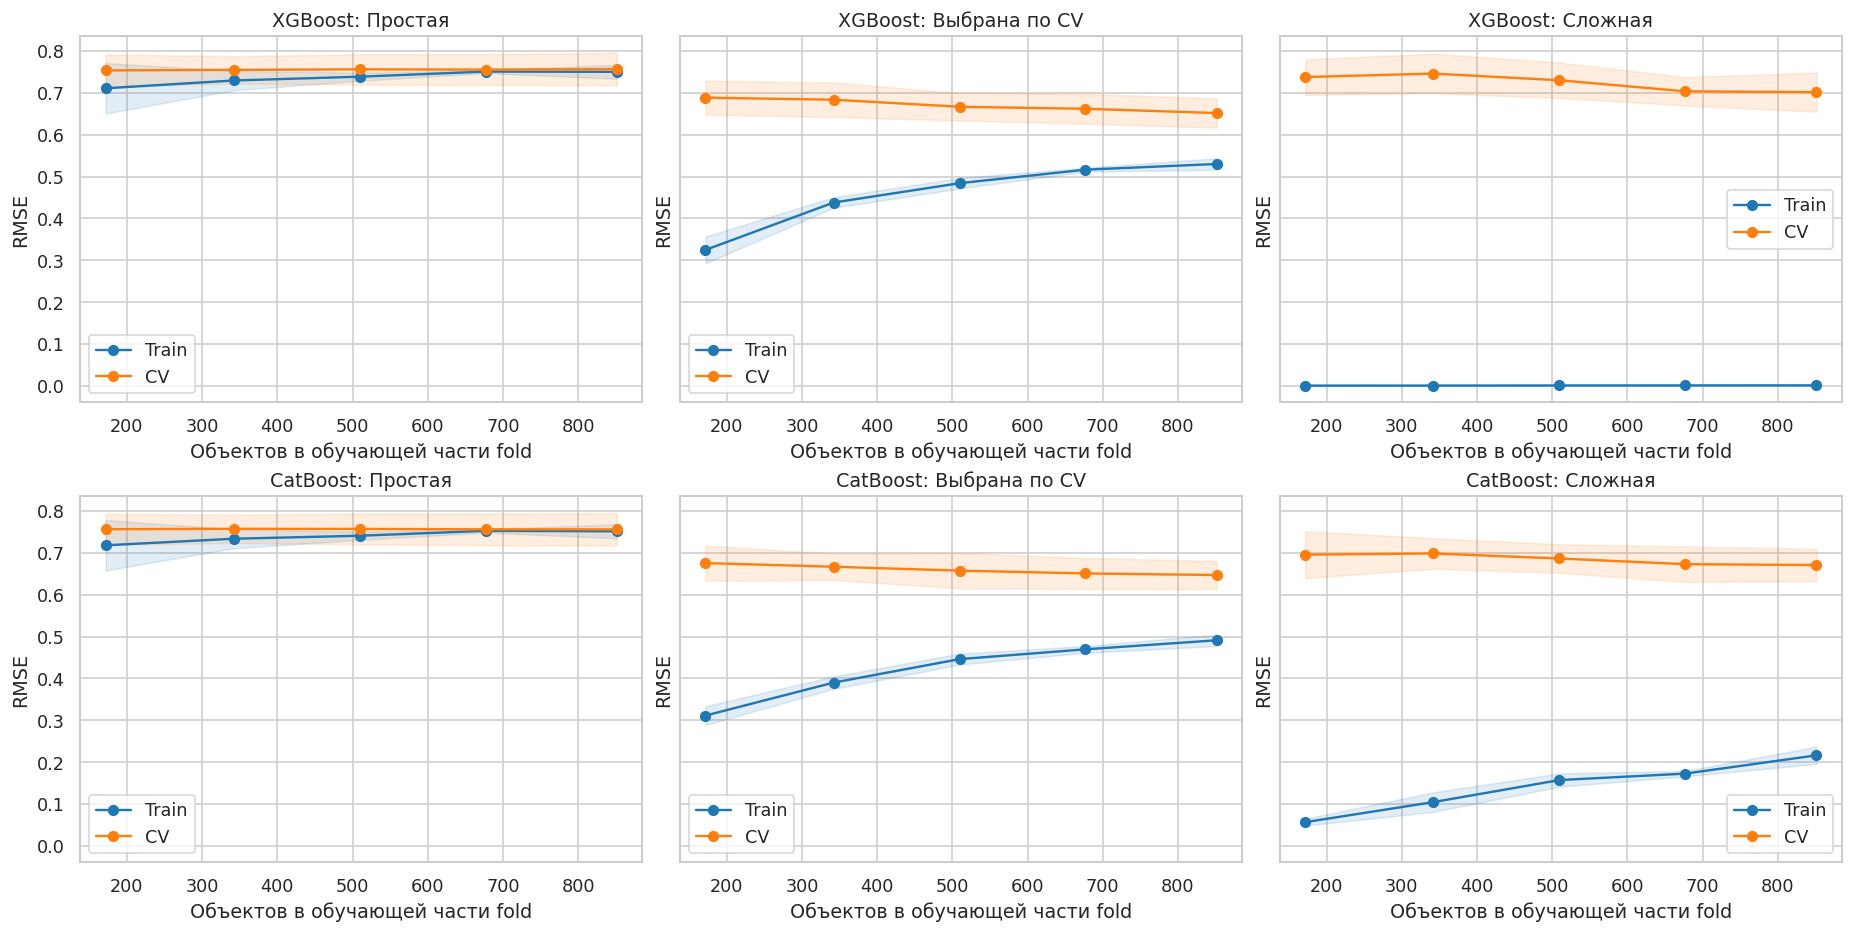

,family,regime,fraction,n_train,train_rmse,train_std,cv_rmse,cv_std
12,XGBoost,Простая,1.0,851.33333,0.75033,0.01662,0.75689,0.03845
13,XGBoost,Выбрана по CV,1.0,851.33333,0.53014,0.01370,0.65187,0.03504
14,XGBoost,Сложная,1.0,851.33333,0.00132,0.00008,0.70173,0.04648
27,CatBoost,Простая,1.0,851.33333,0.75157,0.01670,0.75616,0.03848
28,CatBoost,Выбрана по CV,1.0,851.33333,0.49123,0.01370,0.64709,0.03368
29,CatBoost,Сложная,1.0,851.33333,0.21638,0.02047,0.67098,0.03841


In [17]:
curve_summary = (
    curve_df.groupby(['family', 'regime', 'fraction'], sort=False)
    .agg(n_train=('n_train', 'mean'), train_rmse=('train_rmse', 'mean'),
         train_std=('train_rmse', 'std'), cv_rmse=('cv_rmse', 'mean'), cv_std=('cv_rmse', 'std'))
    .reset_index()
)
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True, constrained_layout=True)
for row, family in enumerate(search_results):
    for col, regime in enumerate(['Простая', 'Выбрана по CV', 'Сложная']):
        part = curve_summary.query('family == @family and regime == @regime').sort_values('fraction')
        x = part.n_train.to_numpy()
        ax = axes[row, col]
        for column, color, label in [('train_rmse', 'tab:blue', 'Train'), ('cv_rmse', 'tab:orange', 'CV')]:
            mean = part[column].to_numpy()
            std = part['train_std' if column == 'train_rmse' else 'cv_std'].to_numpy()
            ax.plot(x, mean, 'o-', color=color, label=label)
            ax.fill_between(x, mean-std, mean+std, color=color, alpha=0.13)
        ax.set(title=f'{family}: {regime}', xlabel='Объектов в обучающей части fold', ylabel='RMSE')
        ax.legend()
fig.savefig(ROOT / 'learning_curves.png', dpi=160)
plt.show()
display(curve_summary[curve_summary.fraction == 1.0].round(5))

In [18]:
for family in search_results:
    full = curve_summary[(curve_summary.family == family) & (curve_summary.fraction == 1.0)].set_index('regime')
    chosen, simple, complex_ = (full.loc[name] for name in ['Выбрана по CV', 'Простая', 'Сложная'])
    simple_note = (
        'У простой модели выше и train-, и CV-ошибка, чем у выбранной: это поддерживает вывод о недообучении.'
        if simple.train_rmse > chosen.train_rmse and simple.cv_rmse > chosen.cv_rmse
        else 'Сравнение простой и выбранной моделей не даёт однозначного признака недообучения; учитываем форму кривых.'
    )
    complex_note = (
        'Усложнение уменьшило train-ошибку и увеличило CV-ошибку: это признак переобучения сложной модели.'
        if complex_.train_rmse < chosen.train_rmse and complex_.cv_rmse > chosen.cv_rmse
        else 'По сравнению с выбранной моделью нет одновременного уменьшения train-ошибки и роста CV-ошибки; переобучение этим сравнением не подтверждено.'
    )
    selected_curve = curve_summary[(curve_summary.family == family) & (curve_summary.regime == 'Выбрана по CV')].sort_values('fraction')
    size_gain = selected_curve.iloc[0].cv_rmse - selected_curve.iloc[-1].cv_rmse
    display(Markdown(
        f'**{family}.** На полной обучающей части fold train/CV RMSE: '
        f'простая модель — {simple.train_rmse:.4f}/{simple.cv_rmse:.4f}; '
        f'выбранная — {chosen.train_rmse:.4f}/{chosen.cv_rmse:.4f}; '
        f'сложная — {complex_.train_rmse:.4f}/{complex_.cv_rmse:.4f}. '
        f'{simple_note} {complex_note} '
        f'При увеличении обучающей части с 20% до 100% CV RMSE выбранной модели изменился на {-size_gain:+.4f}. '
        'Смотрим также на сближение train/CV-кривых и разброс folds. Вывод относится к этим данным и разбиениям; фиксированного универсального порога разрыва нет.'
    ))


**XGBoost.** На полной обучающей части fold train/CV RMSE: простая модель — 0.7503/0.7569; выбранная — 0.5301/0.6519; сложная — 0.0013/0.7017. У простой модели выше и train-, и CV-ошибка, чем у выбранной: это поддерживает вывод о недообучении. Усложнение уменьшило train-ошибку и увеличило CV-ошибку: это признак переобучения сложной модели. При увеличении обучающей части с 20% до 100% CV RMSE выбранной модели изменился на -0.0367. Смотрим также на сближение train/CV-кривых и разброс folds. Вывод относится к этим данным и разбиениям; фиксированного универсального порога разрыва нет.

**CatBoost.** На полной обучающей части fold train/CV RMSE: простая модель — 0.7516/0.7562; выбранная — 0.4912/0.6471; сложная — 0.2164/0.6710. У простой модели выше и train-, и CV-ошибка, чем у выбранной: это поддерживает вывод о недообучении. Усложнение уменьшило train-ошибку и увеличило CV-ошибку: это признак переобучения сложной модели. При увеличении обучающей части с 20% до 100% CV RMSE выбранной модели изменился на -0.0285. Смотрим также на сближение train/CV-кривых и разброс folds. Вывод относится к этим данным и разбиениям; фиксированного универсального порога разрыва нет.

## 10. Фиксация финалистов до открытия test

У каждой реализации остаются четыре решения: исходные параметры, победитель Grid Search, Random Search и Optuna. Основная модель работы — XGBoost; CatBoost — дополнительное исследование. Среди решений каждой реализации выбираем минимум **CV RMSE**, включая baseline. Ни графики test, ни test-метрики не участвуют в этом выборе. Диагностические срезы выше не запускают новую настройку по test.

Сохраняем параметры и правило выбора в `selected_models.json`. После следующей секции параметры не меняем даже в случае неожиданного результата на test.

In [19]:
final_choices = {}
selected_by_cv = {}
for family, methods in search_results.items():
    final_choices[family] = {'Baseline': baseline_results[family]}
    final_choices[family].update({method: result['best'] for method, result in methods.items()})
    winner = min(final_choices[family], key=lambda name: final_choices[family][name]['cv_rmse'])
    selected_by_cv[family] = {
        'method': winner, 'params': final_choices[family][winner]['params'],
        'cv_rmse': final_choices[family][winner]['cv_rmse'],
    }
selection_record = {
    'rule': 'Минимум среднего RMSE на фиксированных CV-folds; test не участвует',
    'primary_family': 'XGBoost',
    'selected_by_cv': selected_by_cv,
    'finalists': {family: {name: result['params'] for name, result in choices.items()}
                  for family, choices in final_choices.items()},
}
(ROOT / 'selected_models.json').write_text(json.dumps(selection_record, ensure_ascii=False, indent=2))
display(pd.DataFrame(selected_by_cv).T)
print('Финалисты зафиксированы. Далее выполняется только финальная оценка test.')

,method,params,cv_rmse
XGBoost,Optuna,"{'n_estimators': 121, 'learning_rate': 0.03315...",0.651869
CatBoost,Optuna,"{'n_estimators': 646, 'learning_rate': 0.00803...",0.647091


Финалисты зафиксированы. Далее выполняется только финальная оценка test.


## 11. Единственная финальная оценка на test

Обучаем зафиксированных финалистов на всей train-части и считаем RMSE и MAE на одном и том же holdout. Добавим константное предсказание средним train как ориентир сложности задачи; baseline самой ЛР №3 — исходный бустинг, а не константа.

MAE — средняя абсолютная ошибка в баллах качества вина. RMSE — корень из среднего квадрата ошибок; он сильнее реагирует на крупные промахи. Даже хороший локальный holdout не гарантирует такой же результат на скрытом тесте преподавателя.

In [20]:
from sklearn.dummy import DummyRegressor

# Повторное выполнение этой секции использует сохранённые финальные оценки.
test_signature = hashlib.sha256(
    X_train.tobytes() + np.asarray(y_train).tobytes()
    + X_test.tobytes() + np.asarray(y_test).tobytes()
).hexdigest()
test_cache_path = ROOT / 'final_test_cache.json'
test_cache = json.loads(test_cache_path.read_text()) if test_cache_path.exists() else {}
final_rows = []
fold_rows = []
for family, choices in final_choices.items():
    for method, result in choices.items():
        params = result['params']
        key = json.dumps([test_signature, family, params], sort_keys=True)
        if key not in test_cache:
            model = make_model(family, params)
            started = time.perf_counter()
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            model_name = f"{family}_{hashlib.sha256(key.encode()).hexdigest()[:12]}"
            model_path = ROOT / (model_name + ('.json' if family == 'XGBoost' else '.cbm'))
            model.save_model(str(model_path))
            test_cache[key] = {
                'Test RMSE': float(np.sqrt(np.mean((y_test-predictions)**2))),
                'Test MAE': float(np.mean(np.abs(y_test-predictions))),
                'Финальное обучение, с': time.perf_counter()-started,
                'Файл модели': model_path.name,
            }
            temporary = test_cache_path.with_suffix('.tmp')
            temporary.write_text(json.dumps(test_cache, ensure_ascii=False, indent=2))
            temporary.replace(test_cache_path)
            del model
        final_rows.append({
            'Модель': family, 'Поиск': method, 'CV RMSE': result['cv_rmse'],
            'CV std': result['cv_std'], 'CV MAE': float(np.mean(result['fold_mae'])),
            **test_cache[key], 'Выбрана по CV': method == selected_by_cv[family]['method'],
            'Параметры': json.dumps(params, sort_keys=True),
        })
        for fold, (fold_rmse, fold_mae) in enumerate(zip(result['fold_rmse'], result['fold_mae']), start=1):
            fold_rows.append({'Модель': family, 'Поиск': method, 'Fold': fold,
                              'RMSE': fold_rmse, 'MAE': fold_mae})

constant_rmse, constant_mae = [], []
for fit_idx, valid_idx in cv_splits:
    dummy = DummyRegressor(strategy='mean').fit(X_train[fit_idx], y_train[fit_idx])
    pred = dummy.predict(X_train[valid_idx])
    constant_rmse.append(float(np.sqrt(np.mean((y_train[valid_idx]-pred)**2))))
    constant_mae.append(float(np.mean(np.abs(y_train[valid_idx]-pred))))
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
pred = dummy.predict(X_test)
final_rows.append({
    'Модель': 'Константа', 'Поиск': 'Среднее train',
    'CV RMSE': np.mean(constant_rmse), 'CV std': np.std(constant_rmse, ddof=1),
    'CV MAE': np.mean(constant_mae),
    'Test RMSE': float(np.sqrt(np.mean((y_test-pred)**2))),
    'Test MAE': float(np.mean(np.abs(y_test-pred))), 'Выбрана по CV': False,
    'Параметры': 'strategy=mean',
})
final_table = pd.DataFrame(final_rows)
fold_table = pd.DataFrame(fold_rows)
final_table.to_csv(ROOT / 'final_results.csv', index=False)
fold_table.to_csv(ROOT / 'cv_fold_results.csv', index=False)
display(final_table.drop(columns=['Файл модели', 'Параметры'], errors='ignore').round(5))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:729: UserWarning: [20:03:35] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,Модель,Поиск,CV RMSE,CV std,CV MAE,Test RMSE,Test MAE,"Финальное обучение, с",Выбрана по CV
0,XGBoost,Baseline,0.66032,0.03744,0.50967,0.60279,0.47438,0.21589,False
1,XGBoost,Grid,0.65363,0.03430,0.50594,0.60434,0.47537,0.37724,False
2,XGBoost,Random,0.65338,0.03441,0.50577,0.60369,0.47509,0.44186,False
3,XGBoost,Optuna,0.65187,0.03504,0.50571,0.60691,0.47665,0.10846,True
4,CatBoost,Baseline,0.65010,0.03555,0.50736,0.60498,0.47419,0.26144,False
5,CatBoost,Grid,0.64791,0.03496,0.50507,0.60271,0.46881,7.16959,False
6,CatBoost,Random,0.64778,0.03318,0.50338,0.59991,0.46609,10.27307,False
7,CatBoost,Optuna,0.64709,0.03368,0.50311,0.60172,0.46746,10.53761,True
8,Константа,Среднее train,0.80215,0.03943,0.68025,0.82657,0.69334,NaN,False


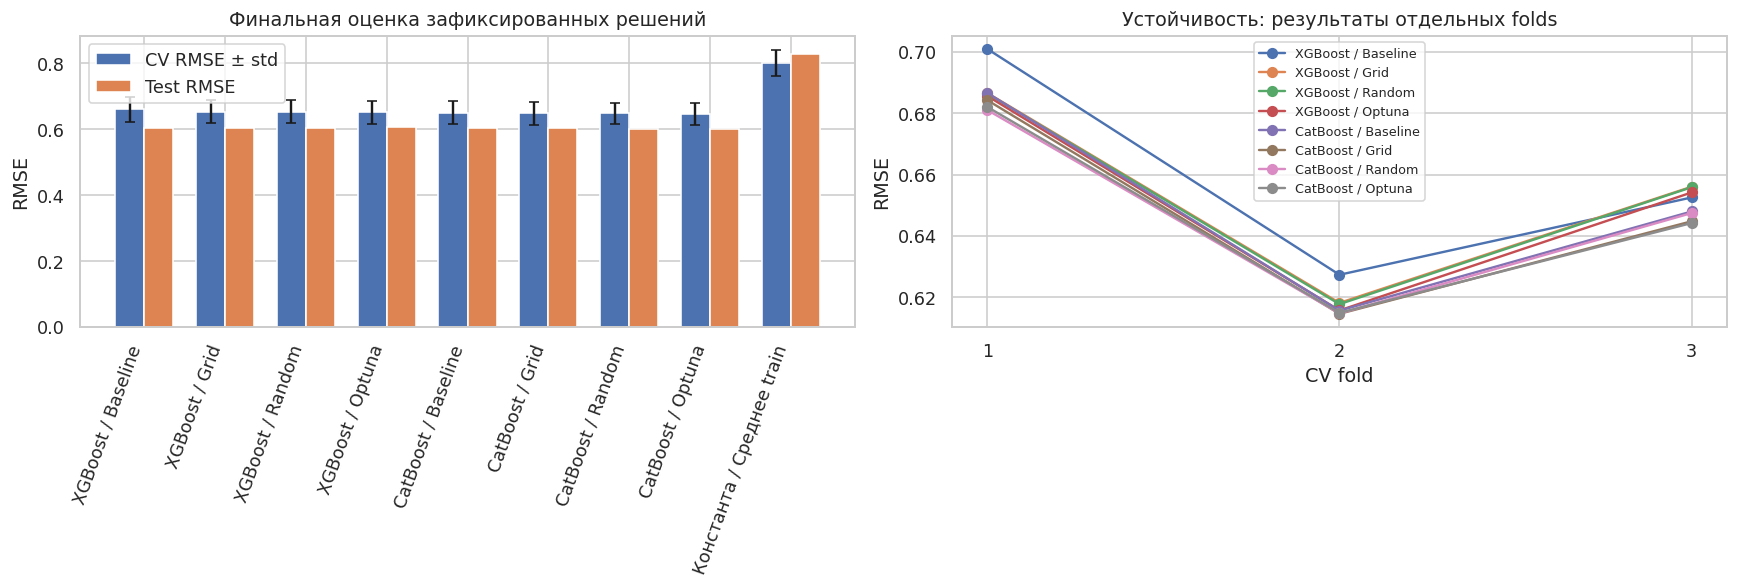

Fold                     1        2        3
Модель   Поиск                              
CatBoost Baseline  0.68666  0.61565  0.64800
         Grid      0.68432  0.61461  0.64480
         Optuna    0.68211  0.61494  0.64423
         Random    0.68111  0.61475  0.64749
XGBoost  Baseline  0.70103  0.62735  0.65257
         Grid      0.68664  0.61818  0.65607
         Optuna    0.68568  0.61572  0.65420
         Random    0.68644  0.61777  0.65592

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
labels = final_table['Модель'] + ' / ' + final_table['Поиск']
x = np.arange(len(final_table))
axes[0].bar(x-0.18, final_table['CV RMSE'], width=0.36,
            yerr=final_table['CV std'], capsize=3, label='CV RMSE ± std')
axes[0].bar(x+0.18, final_table['Test RMSE'], width=0.36, label='Test RMSE')
axes[0].set_xticks(x, labels, rotation=70, ha='right')
axes[0].set(ylabel='RMSE', title='Финальная оценка зафиксированных решений')
axes[0].legend()
for family in final_choices:
    for method in final_choices[family]:
        part = fold_table[(fold_table['Модель'] == family) & (fold_table['Поиск'] == method)]
        axes[1].plot(part.Fold, part.RMSE, 'o-', label=f'{family} / {method}')
axes[1].set(xticks=np.arange(1, len(cv_splits)+1), xlabel='CV fold', ylabel='RMSE',
            title='Устойчивость: результаты отдельных folds')
axes[1].legend(fontsize=8)
fig.savefig(ROOT / 'final_comparison.png', dpi=160)
plt.show()
display(fold_table.pivot(index=['Модель', 'Поиск'], columns='Fold', values='RMSE').round(5))

## 12. Что показывает эксперимент

**Зачем нужна кросс-валидация?** Каждый объект train-части проверяется моделью, которая не обучалась на его группе. Усреднение по нескольким разбиениям уменьшает зависимость выбора параметров от одного удачного validation-набора. Одного train/test-разбиения для многократной настройки недостаточно: если подбирать по test, он фактически становится validation и оценка качества делается оптимистичной. Поэтому test здесь открывается после сохранения финалистов.

**Почему Random Search иногда выгоднее полного перебора?** В многомерном пространстве обычно не все параметры одинаково важны. Случайные точки исследуют больше различных значений каждого существенного параметра при заданном числе проверок, тогда как декартова сетка тратит часть бюджета на сочетания мало влияющих параметров. Для небольшой сетки и выраженных взаимодействий Grid Search остаётся понятным и систематическим ориентиром. В данной работе сравнение относится к конкретным пространствам и seed.

**Чем отличается Optuna?** TPE использует результаты предыдущих проверок и предлагает точки, перспективные с точки зрения своей вероятностной модели. Это последовательная байесовская оптимизация, а не заранее независимый случайный выбор. Уточнение пространства вокруг лучшей широкой точки может помочь, но может также закрепить выбор локально удачной области. Гарантии нахождения глобального оптимума нет.

**Почему CV и test могут расходиться?** Это разные конечные выборки; группы и редкие оценки качества распределяются в них неодинаково. Кроме того, CV многократно используется для выбора среди кандидатов, и минимум CV имеет смещение отбора. Численный выигрыш на CV поэтому не обязан повториться на test. Изменять параметры после обнаружения расхождения нельзя: для нового цикла разработки понадобилась бы новая независимая проверка.

**Почему одинаковое среднее не означает одинаковую устойчивость?** Одна модель может давать похожую ошибку во всех folds, другая — очень хорошую в одном и плохую в другом. Смотрим на сами fold scores и их стандартное отклонение, а не только на среднее. Три fold — ограниченная оценка; близкие результаты нельзя объявлять статистически различными только по месту в таблице.

**Как учитывать GPU?** Все основные обучения запрашивают GPU, кандидаты выполняются последовательно. На небольшом Wine Quality GPU не гарантирует ускорения относительно CPU: есть стоимость подготовки и передачи данных. CatBoost на GPU допускает небольшую недетерминированность вычислений даже при фиксированном seed. Сохранённые версии пакетов, параметры, разбиения и результаты нужны для воспроизводимости эксперимента.

In [25]:
conclusions = []
for family in final_choices:
    part = final_table[final_table['Модель'] == family].set_index('Поиск')
    baseline = part.loc['Baseline']
    chosen_method = selected_by_cv[family]['method']
    chosen = part.loc[chosen_method]
    cv_gain = baseline['CV RMSE']-chosen['CV RMSE']
    test_gain = baseline['Test RMSE']-chosen['Test RMSE']
    sign_text = 'совпали' if np.sign(cv_gain) == np.sign(test_gain) else 'не совпали'
    conclusions.append(
        f"**{family}.** По CV выбрана стратегия **{chosen_method}**. "
        f"Исходная модель: CV RMSE {baseline['CV RMSE']:.4f}, test RMSE {baseline['Test RMSE']:.4f}. "
        f"Зафиксированная модель: CV RMSE {chosen['CV RMSE']:.4f} ± {chosen['CV std']:.4f}, "
        f"test RMSE {chosen['Test RMSE']:.4f}, test MAE {chosen['Test MAE']:.4f}. "
        f"Изменение RMSE относительно baseline (baseline − итог): CV {cv_gain:+.4f}, "
        f"test {test_gain:+.4f}; положительное число означает улучшение. "
        f"Направления изменения {sign_text}."
    )
    methods = search_comparison[search_comparison['Модель'] == family]
    quality_winner = methods.loc[methods['CV RMSE'].idxmin()]
    fastest = methods.loc[methods['Время, мин'].idxmin()]
    conclusions.append(
        f"В этом запуске лучший CV среди трёх поисков у **{quality_winner['Поиск']}** "
        f"({quality_winner['CV RMSE']:.4f}); минимальное измеренное время — у "
        f"**{fastest['Поиск']}** ({fastest['Время, мин']:.2f} мин). "
        "Время зависит от сложности проверенных конфигураций и накладных расходов оптимизатора; паузы между сессиями не включены."
    )
main = selected_by_cv['XGBoost']
conclusions.append(
    f"Основной итог лабораторной — **XGBoost / {main['method']}**, выбранный до test. "
    "CatBoost сравнивается как дополнительное исследование. "
    "Эти результаты не устанавливают качество на скрытой тестовой выборке и не доказывают "
    "универсальное превосходство одной библиотеки или стратегии поиска."
)
# Объяснение наблюдаемых срезов строится только по train/CV.
influence_table = pd.DataFrame(influence_rows)
for family in final_choices:
    observations = []
    for parameter in ['n_estimators', 'learning_rate', 'max_depth']:
        part = influence_table[(influence_table.family == family) & (influence_table.parameter == parameter)].sort_values('value')
        best_slice = part.loc[part.cv_rmse.idxmin()]
        last = part.iloc[-1]
        sentence = (f"`{parameter}`: минимум CV RMSE {best_slice.cv_rmse:.4f} "
                    f"при {best_slice.value:g}; на верхней границе {last.value:g} "
                    f"train/CV RMSE = {last.train_rmse:.4f}/{last.cv_rmse:.4f}.")
        if last.train_rmse < best_slice.train_rmse and last.cv_rmse > best_slice.cv_rmse:
            sentence += ' После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV.'
        else:
            sentence += ' Верхняя граница сама по себе не даёт лучшего качества; учитываем весь срез и разброс folds.'
        observations.append(sentence)
    conclusions.append(f"**Локальные срезы {family}.** " + ' '.join(observations)
                       + ' Остальные параметры фиксированы; найденный минимум относится к этому срезу, а близкие значения не доказывают статистически значимого различия.')

display(Markdown('\n\n'.join(conclusions)))
(ROOT / 'conclusions.md').write_text('\n\n'.join(conclusions), encoding='utf-8')
print('Результаты, параметры, модели и графики сохранены в:', ROOT)

**XGBoost.** По CV выбрана стратегия **Optuna**. Исходная модель: CV RMSE 0.6603, test RMSE 0.6028. Зафиксированная модель: CV RMSE 0.6519 ± 0.0350, test RMSE 0.6069, test MAE 0.4767. Изменение RMSE относительно baseline (baseline − итог): CV +0.0084, test -0.0041; положительное число означает улучшение. Направления изменения не совпали.

В этом запуске лучший CV среди трёх поисков у **Optuna** (0.6519); минимальное измеренное время — у **Optuna** (1.76 мин). Время зависит от сложности проверенных конфигураций и накладных расходов оптимизатора; паузы между сессиями не включены.

**CatBoost.** По CV выбрана стратегия **Optuna**. Исходная модель: CV RMSE 0.6501, test RMSE 0.6050. Зафиксированная модель: CV RMSE 0.6471 ± 0.0337, test RMSE 0.6017, test MAE 0.4675. Изменение RMSE относительно baseline (baseline − итог): CV +0.0030, test +0.0033; положительное число означает улучшение. Направления изменения совпали.

В этом запуске лучший CV среди трёх поисков у **Optuna** (0.6471); минимальное измеренное время — у **Grid** (37.75 мин). Время зависит от сложности проверенных конфигураций и накладных расходов оптимизатора; паузы между сессиями не включены.

Основной итог лабораторной — **XGBoost / Optuna**, выбранный до test. CatBoost сравнивается как дополнительное исследование. Эти результаты не устанавливают качество на скрытой тестовой выборке и не доказывают универсальное превосходство одной библиотеки или стратегии поиска.

**Локальные срезы XGBoost.** `n_estimators`: минимум CV RMSE 0.6519 при 121; на верхней границе 1500 train/CV RMSE = 0.2228/0.6948. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. `learning_rate`: минимум CV RMSE 0.6519 при 0.0331591; на верхней границе 0.2 train/CV RMSE = 0.3289/0.6758. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. `max_depth`: минимум CV RMSE 0.6519 при 3; на верхней границе 9 train/CV RMSE = 0.0999/0.6951. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. Остальные параметры фиксированы; найденный минимум относится к этому срезу, а близкие значения не доказывают статистически значимого различия.

**Локальные срезы CatBoost.** `n_estimators`: минимум CV RMSE 0.6469 при 750; на верхней границе 1500 train/CV RMSE = 0.4233/0.6498. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. `learning_rate`: минимум CV RMSE 0.6471 при 0.00803531; на верхней границе 0.2 train/CV RMSE = 0.2313/0.6831. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. `max_depth`: минимум CV RMSE 0.6471 при 8; на верхней границе 9 train/CV RMSE = 0.4770/0.6486. После минимума CV дальнейшее увеличение параметра улучшает подгонку train и ухудшает CV. Остальные параметры фиксированы; найденный минимум относится к этому срезу, а близкие значения не доказывают статистически значимого различия.

Результаты, параметры, модели и графики сохранены в: /content/drive/MyDrive/MAI_lab03_hyperparameters/results


## Источники

- [Методичка ЛР №3](lab03.pdf): оптимизация гиперпараметров, честный CV/test-протокол, устойчивость.
- [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), P. Cortez et al., 2009. Использована таблица красных вин; задача — прогноз `quality` по физико-химическим измерениям.
- [XGBoost: обучение на GPU](https://xgboost.readthedocs.io/en/stable/gpu/index.html) и [параметры](https://xgboost.readthedocs.io/en/stable/parameter.html).
- [CatBoost: обучение на GPU](https://catboost.ai/docs/en/features/training-on-gpu) и [подбор параметров](https://catboost.ai/docs/en/concepts/parameter-tuning).
- [Optuna TPESampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html).

## 13. Сохранение результата
Архив включает таблицы, кривые, модели, данные и checkpoints. Скачанный выполненный ноутбук содержит все пояснения и результаты ячеек.

In [27]:
# Проверяем полный результат перед созданием архива.
assert sum(r['n_candidates'] for methods in search_results.values() for r in methods.values()) == 1014
assert len(curve_df) == 90 and len(curve_summary) == 30
assert len(final_table) == 9 and len(fold_table) == 24
score_columns = ['CV RMSE', 'CV std', 'Test RMSE', 'Test MAE']
assert np.isfinite(final_table[score_columns].to_numpy(dtype=float)).all()
assert all((ROOT / name).is_file() for name in final_table['Файл модели'].dropna())
assert (ROOT / 'selected_models.json').is_file()
print('Проверено: 1014 CV-конфигураций, 90 точек learning curves, 9 итоговых строк, 24 fold scores.')
archive_path = shutil.make_archive('/content/lab03_results', 'zip', ROOT.parent, ROOT.name)
persistent_archive = ROOT.parent / 'lab03_results.zip'
shutil.copy2(archive_path, persistent_archive)
print('LAB03_COMPLETE:', persistent_archive, flush=True)
from google.colab import files
files.download(archive_path)


Проверено: 1014 CV-конфигураций, 90 точек learning curves, 9 итоговых строк, 24 fold scores.
LAB03_COMPLETE: /content/drive/MyDrive/MAI_lab03_hyperparameters/lab03_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>